# BFGS and DFP Quasi-Newton Optimization

Compare two inverse-Hessian update rules on the two-dimensional Rosenbrock function, starting at $(-1.2,1)$ with an identity inverse-Hessian approximation. Both methods use the same Armijo line search and gradient-norm stopping criterion.

[Technical notes](../docs/bfgs_and_dfp.md) · [Saved figures](../results/bfgs_and_dfp/)

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os
import time

## Rosenbrock objective and gradient

$$f(x)=100(x_2-x_1^2)^2+(1-x_1)^2.$$ The unique global minimizer is $(1,1)$.

In [10]:
def f(x):
    return 100.0 * (x[1] - x[0]**2)**2 + (1 - x[0])**2

def grad_f(x):
    dfdx1 = -400*x[0]*(x[1]-x[0]**2) - 2*(1-x[0])
    dfdx2 = 200*(x[1]-x[0]**2)
    return np.array([dfdx1, dfdx2])

## Armijo backtracking

Start with unit trial step, reduce by 0.5 and enforce sufficient decrease with $c_1=10^{-4}$.

In [11]:
def backtracking(x, p, g, alpha0=1.0, rho=0.5, c1=1e-4):
    alpha = alpha0
    fx = f(x)
    while f(x + alpha*p) > fx + c1*alpha*np.dot(g, p):
        alpha *= rho
    return alpha


## DFP inverse-Hessian update

For $s=x_{k+1}-x_k$, $y=g_{k+1}-g_k$,

$$H_{k+1}=H_k+\frac{ss^T}{y^Ts}-\frac{H_kyy^TH_k}{y^TH_ky}.$$

In [12]:
def dfp_update(H, s, y):
    ys = np.dot(y, s)
    Hy = H @ y
    return H + np.outer(s, s)/ys - np.outer(Hy, Hy)/(y @ Hy)

## BFGS inverse-Hessian update

$$H_{k+1}=(I-\rho sy^T)H_k(I-\rho ys^T)+\rho ss^T,\quad \rho=(y^Ts)^{-1}.$$

In [13]:
def bfgs_update(H, s, y):
    ys = np.dot(y, s)
    rho = 1.0 / ys
    I = np.eye(len(s))
    return (I - rho*np.outer(s, y)) @ H @ (I - rho*np.outer(y, s)) + rho*np.outer(s, s)

## Shared quasi-Newton solver

Compute $p=-H_kg_k$, perform backtracking and update the approximation with the selected formula. Record the iterate, objective and gradient norm. The limit is 500 iterations and the gradient tolerance is $10^{-6}$.

In [16]:
def quasi_newton(method="BFGS", max_iter=500, tol=1e-6):
    x = np.array([-1.2, 1.0])   # initial point
    H = np.eye(2)
    history = []

    for k in range(max_iter):
        g = grad_f(x)
        history.append([x[0], x[1], f(x), np.linalg.norm(g)])

        if np.linalg.norm(g) < tol:
            break

        p = -H @ g
        alpha = backtracking(x, p, g)
        x_new = x + alpha*p

        s = x_new - x
        y = grad_f(x_new) - g

        if method == "DFP":
            H = dfp_update(H, s, y)
        else:
            H = bfgs_update(H, s, y)

        x = x_new

    return np.array(history)

## Execute both update rules

Use identical initial conditions.

In [17]:
os.makedirs("outputs", exist_ok=True)

hist_dfp = quasi_newton("DFP")
hist_bfgs = quasi_newton("BFGS")

## Objective and gradient-norm convergence

Logarithmic scales reveal the late-stage convergence behavior.

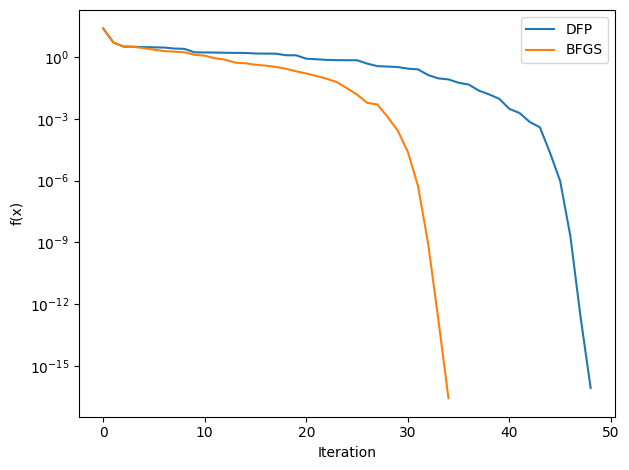

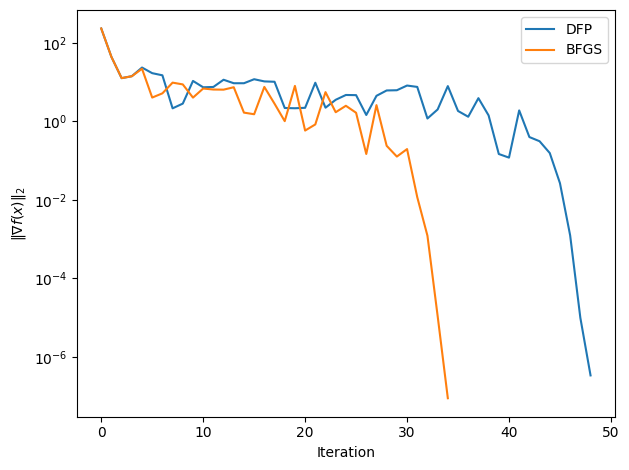

In [18]:
plt.figure()
plt.semilogy(hist_dfp[:,2], label="DFP")
plt.semilogy(hist_bfgs[:,2], label="BFGS")
plt.xlabel("Iteration")
plt.ylabel("f(x)")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/rosenbrock_loss.png", dpi=300)
plt.show()
plt.close()

plt.figure()
plt.semilogy(hist_dfp[:,3], label="DFP")
plt.semilogy(hist_bfgs[:,3], label="BFGS")
plt.xlabel("Iteration")
plt.ylabel(r"$\|\nabla f(x)\|_2$")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/rosenbrock_gradnorm.png", dpi=300)
plt.show()
plt.close()



## Results and interpretation

The saved objective and gradient-norm plots show that BFGS reaches the small-gradient regime sooner than DFP. BFGS ends near iteration 34 and DFP near iteration 48 (approximate indices read from the plots). Both obtain very small objective values; BFGS shows a faster late-stage decline in this particular experiment.

The comparison is limited to one starting point and one objective. The inverse-Hessian updates assume nonzero denominators and appropriate curvature (in particular $s^Ty>0$ for preservation of positive definiteness). The code does not guard against all curvature breakdowns, and Armijo alone does not guarantee the usual Wolfe curvature condition. These are limitations of the implementation, not evidence that they occurred in the displayed experiment.